<a href="https://colab.research.google.com/github/shivaprasannatejadharma-arch/ML_LAB_2026-27/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Employee Salary Prediction Using Machine Learning**

**Aim:** To predict an employee's salary based on experience, education, age, job role, and other employee details using machine learning algorithms.

**Project Description:** This project uses machine learning to estimate employee salaries based on their details. Five regression algorithms are trained and compared to identify the best-performing model.

**1. Import the required libraries**

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

**2.Create and load the dataset**

For this beginner project, we create a sample employee salary dataset using Python. You do not need to download a CSV file separately.

In [12]:
np.random.seed(42)

data = pd.DataFrame({
    "Age": np.random.randint(21, 55, 200),
    "Experience": np.random.randint(0, 25, 200),
    "Education": np.random.choice(
        ["Graduate", "Postgraduate", "PhD"], 200
    ),
    "Job_Role": np.random.choice(
        ["Developer", "Manager", "Analyst", "HR", "Designer"], 200
    ),
    "Working_Hours": np.random.randint(30, 55, 200)
})

education_bonus = data["Education"].map({
    "Graduate": 5000,
    "Postgraduate": 12000,
    "PhD": 20000
})

role_bonus = data["Job_Role"].map({
    "Developer": 10000,
    "Manager": 20000,
    "Analyst": 7000,
    "HR": 5000,
    "Designer": 6000
})

data["Salary"] = (
    15000
    + data["Experience"] * 4000
    + education_bonus
    + role_bonus
    + data["Working_Hours"] * 300
    + np.random.normal(0, 5000, 200)
)

data["Salary"] = data["Salary"].round(2)

data.to_csv("employee_salary_dataset.csv", index=False)

print(data.head())
print("\nDataset Shape:", data.shape)
print("\nMissing Values:\n", data.isnull().sum())

   Age  Experience     Education  Job_Role  Working_Hours     Salary
0   49          19           PhD  Designer             49  125647.49
1   35          23      Graduate   Manager             44  137132.95
2   28          21  Postgraduate        HR             44  125464.46
3   41          23  Postgraduate  Designer             53  141174.60
4   39           0  Postgraduate  Designer             51   49510.08

Dataset Shape: (200, 6)

Missing Values:
 Age              0
Experience       0
Education        0
Job_Role         0
Working_Hours    0
Salary           0
dtype: int64


**3. Separate input and output**
- Input (X): Employee details such as age, experience, education, job role and working hours.
- Output (y): Employee salary.

In [13]:
X = data.drop("Salary", axis=1)
y = data["Salary"]

print("Input Features:", list(X.columns))
print("Output:", "Salary")

Input Features: ['Age', 'Experience', 'Education', 'Job_Role', 'Working_Hours']
Output: Salary


**4. Convert categorical data into numerical data**
Machine learning algorithms work with numerical values. Therefore, we convert education and job role into numbers using one-hot encoding.

In [14]:
X = pd.get_dummies(X, columns=["Education", "Job_Role"])

print(X.head())

   Age  Experience  Working_Hours  Education_Graduate  Education_PhD  \
0   49          19             49               False           True   
1   35          23             44                True          False   
2   28          21             44               False          False   
3   41          23             53               False          False   
4   39           0             51               False          False   

   Education_Postgraduate  Job_Role_Analyst  Job_Role_Designer  \
0                   False             False               True   
1                   False             False              False   
2                    True             False              False   
3                    True             False               True   
4                    True             False               True   

   Job_Role_Developer  Job_Role_HR  Job_Role_Manager  
0               False        False             False  
1               False        False              True  
2    

**5. Split the dataset**

We divide the dataset into training and testing data.
- 80% data for training.
- 20% data for testing.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (160, 11)
Testing Data: (40, 11)


**6. Apply five machine learning algorithms**

We use five regression algorithms to predict employee salaries.
1. Linear Regression
2. Decision Tree Regression
3. Random Forest Regression
4. KNN Regression
5. Support Vector Regression (SVR)

In [16]:
models = {
    "Linear Regression": make_pipeline(
        StandardScaler(), LinearRegression()
    ),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "KNN": make_pipeline(
        StandardScaler(), KNeighborsRegressor(n_neighbors=5)
    ),

    "SVR": make_pipeline(
        StandardScaler(), SVR()
    )
}

results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results[name] = r2

    print("\n", name)
    print("MAE:", round(mae, 2))
    print("R2 Score:", round(r2, 3))


 Linear Regression
MAE: 5045.45
R2 Score: 0.968

 Decision Tree
MAE: 8604.8
R2 Score: 0.897

 Random Forest
MAE: 6987.54
R2 Score: 0.927

 KNN
MAE: 19932.01
R2 Score: 0.503

 SVR
MAE: 29014.94
R2 Score: -0.025


**7. Compare model performance**

We compare all five algorithms using their R² scores.

           Algorithm  R2 Score
0  Linear Regression  0.968387
2      Random Forest  0.927007
1      Decision Tree  0.896873
3                KNN  0.503066
4                SVR -0.024746


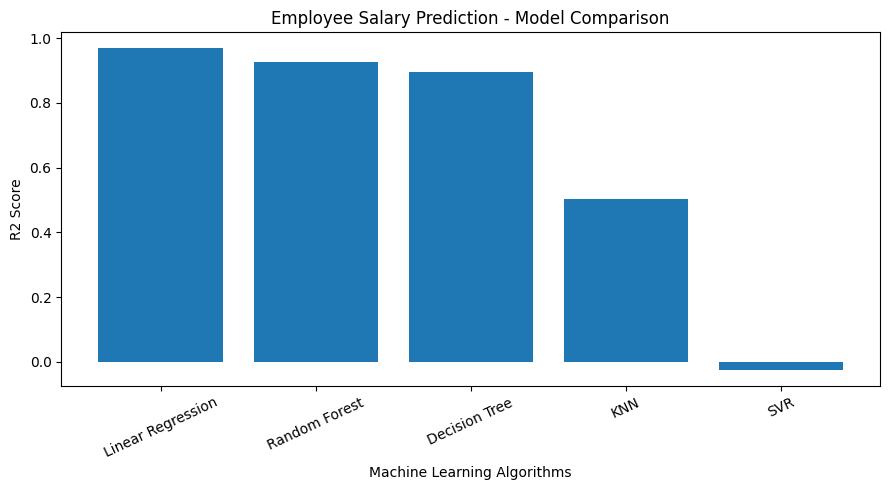

In [17]:
results_df = pd.DataFrame({
    "Algorithm": list(results.keys()),
    "R2 Score": list(results.values())
})

results_df = results_df.sort_values(
    "R2 Score", ascending=False
)

print(results_df)

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Algorithm"],
    results_df["R2 Score"]
)

plt.xlabel("Machine Learning Algorithms")
plt.ylabel("R2 Score")
plt.title("Employee Salary Prediction - Model Comparison")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

**8. Select the best model**

The algorithm with the highest R² score is selected as the best model.

In [18]:
best_name = max(results, key=results.get)

best_model = models[best_name]

print("Best Model:", best_name)

predictions = best_model.predict(X_test)

print("\nActual Salary vs Predicted Salary")

comparison = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": predictions
})

print(comparison.head(10))

Best Model: Linear Regression

Actual Salary vs Predicted Salary
   Actual Salary  Predicted Salary
0      141704.71     137227.694498
1      108539.22     104398.308102
2       36836.32      40039.315527
3       67703.24      70514.158182
4       56815.77      50044.158508
5      130645.75     139804.979501
6       80077.36      79611.223234
7      135805.69     137751.083639
8      152219.49     144427.164492
9      133223.52     125076.182269


**9. Predict the salary of a new employee**

We provide new employee details to predict their salary.

In [19]:
new_employee = pd.DataFrame([{
    "Age": 25,
    "Experience": 2,
    "Working_Hours": 40,
    "Education": "Graduate",
    "Job_Role": "Developer"
}])

new_employee = pd.get_dummies(
    new_employee,
    columns=["Education", "Job_Role"]
)

new_employee = new_employee.reindex(
    columns=X.columns,
    fill_value=0
)

predicted_salary = best_model.predict(new_employee)

print(
    "Predicted Employee Salary: ₹",
    round(predicted_salary[0], 2)
)

Predicted Employee Salary: ₹ 51409.63


**10. Conclusion**

In this project, we developed an Employee Salary Prediction System using Machine Learning.
- We created an employee dataset containing 200 records.
- We used five machine learning algorithms.

  Linear Regression



  Decision Tree Regression



  Random Forest Regression



  K-Nearest Neighbors (KNN)



  Support Vector Regression (SVR)
- We trained and tested the models.
- We compared their performance using R² scores.
- We selected the best-performing model.
- Finally, we predicted the salary of a new employee.

**Note:** This project is created for learning and understanding how machine learning can be used in employee salary prediction.